In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
ROOT = "/content/drive/MyDrive/simuteh-2330511068"
print(os.listdir(ROOT))
print(os.listdir(f"{ROOT}/src"))

%cd {ROOT}/notebook
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak
print("OK")

Mounted at /content/drive
['data', 'notebook', 'src', 'hasil', 'laporan', 'requirements.txt']
['buat_dataset_sintetis.py', 'utils_cv.py', '__pycache__']
/content/drive/MyDrive/simuteh-2330511068/notebook
OK


In [3]:
bercak_rgb = (196, 178, 86)
daun_rgb = (52, 136, 60)

def gray_manual(rgb):
    r, g, b = rgb
    return 0.299 * r + 0.587 * g + 0.114 * b

print("Y manual   bercak:", round(gray_manual(bercak_rgb), 2), "| daun:", round(gray_manual(daun_rgb), 2))

# cv2 memakai urutan BGR
px = np.array([[bercak_rgb[::-1], daun_rgb[::-1]]], dtype=np.uint8)   # 1x2x3
print("Gray cv2   :", cv2.cvtColor(px, cv2.COLOR_BGR2GRAY)[0])
print("HSV cv2    :", cv2.cvtColor(px, cv2.COLOR_BGR2HSV)[0])         # H: 0..179

Y manual   bercak: 172.89 | daun: 102.22
Gray cv2   : [173 102]
HSV cv2    : [[ 25 143 196]
 [ 63 158 136]]


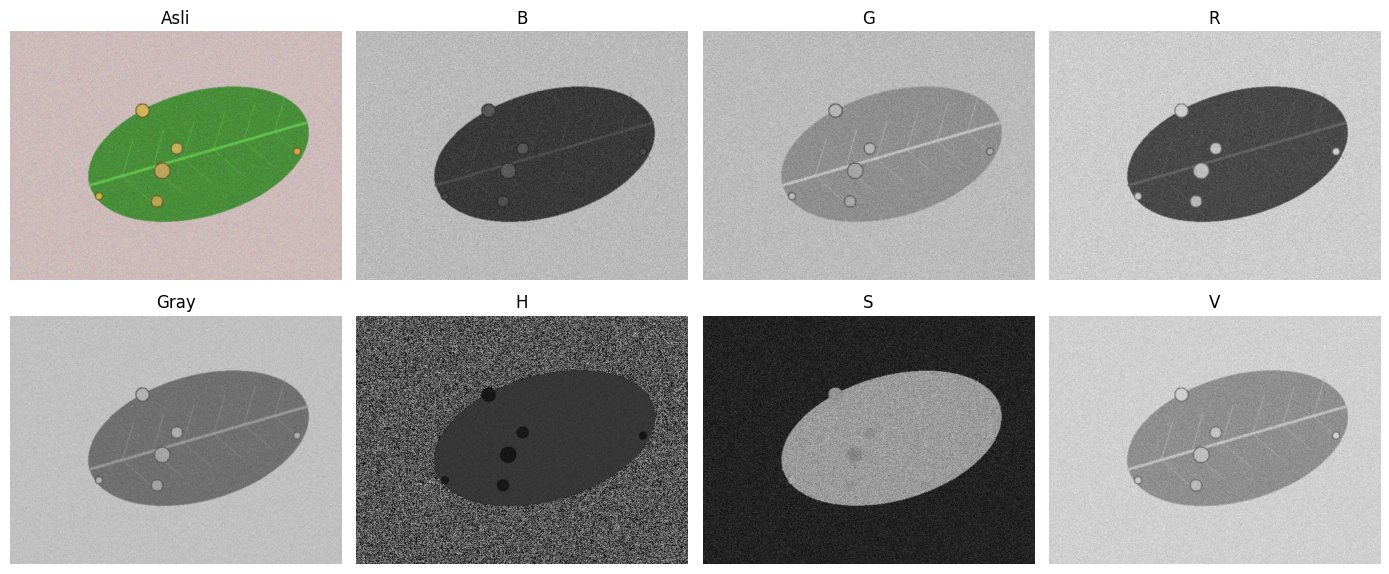

KB kanal B   : 1.06
KB kanal G   : 0.29
KB kanal R   : 6.80
KB kanal Gray: 3.02
KB kanal H   : 5.12
KB kanal S   : 0.39
KB kanal V   : 1.73


In [4]:
nama = "teh_041.png"
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
plt.savefig("../hasil/b2_panel_kanal.png", dpi=150)
plt.show()

for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

--- Sampling ---
fx=0.5: ukuran (240, 320), KB=4.05
fx=0.2: ukuran (96, 128), KB=4.01
fx=0.1: ukuran (48, 64), KB=2.97
fx=0.05: ukuran (24, 32), KB=1.42
--- Kuantisasi ---
k=1: 2 level, KB=2.38
k=2: 3 level, KB=2.40
k=3: 6 level, KB=3.17
k=4: 11 level, KB=2.77
k=8: 158 level, KB=3.02


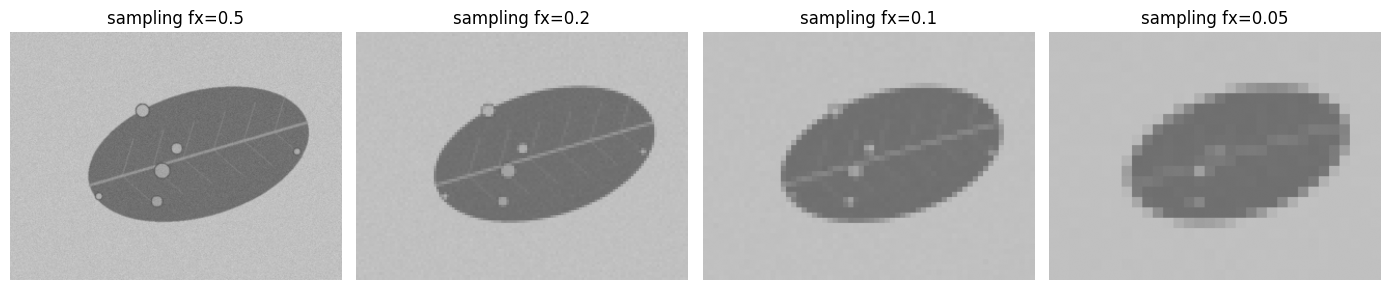

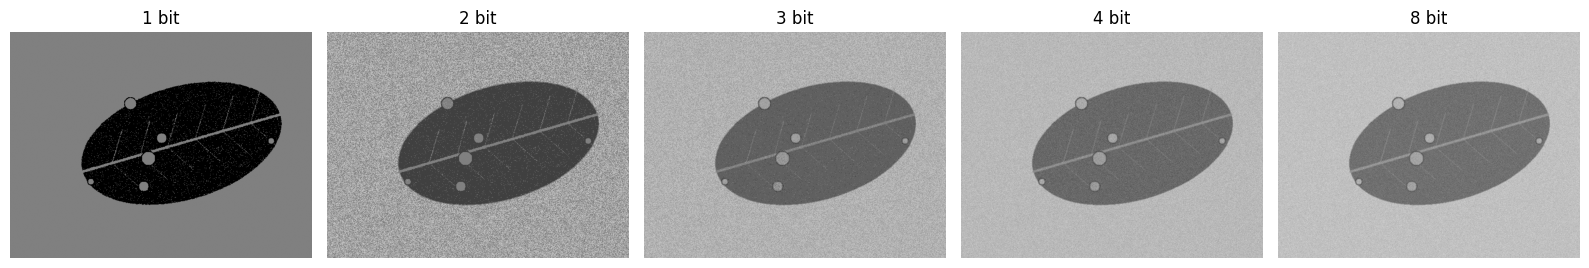

In [5]:
print("--- Sampling ---")
hasil_sampling = []
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    kb = kontras_bercak(besar, md, mb)
    hasil_sampling.append((fx, besar))
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kb:.2f}")

print("--- Kuantisasi ---")
hasil_kuant = []
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    hasil_kuant.append((k, kuant))
    print(f"k={k}: {len(np.unique(kuant))} level, KB={kontras_bercak(kuant, md, mb):.2f}")

# tampilkan berdampingan (diminta Langkah 2.4)
tampil([besar for _, besar in hasil_sampling],
       [f"sampling fx={fx}" for fx, _ in hasil_sampling], ukuran=(14, 4))
plt.savefig("../hasil/b2_sampling.png", dpi=150); plt.show()
tampil([kuant for _, kuant in hasil_kuant],
       [f"{k} bit" for k, _ in hasil_kuant], ukuran=(16, 4))
plt.savefig("../hasil/b2_kuantisasi.png", dpi=150); plt.show()

In [6]:
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

urutan = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2).reindex(urutan)
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
normal          1.72  1.01   7.46  3.98  5.08  0.81  2.35
gelap           1.33  1.60  10.54  4.88  5.88  0.87  3.40
terang          2.07  0.37   6.31  3.24  5.09  1.11  1.55
kontras_rendah  0.94  0.56   3.97  2.33  1.87  0.14  1.59
bayangan        1.48  0.69   5.87  2.14  4.23  0.86  1.40
